# CSE457 • XỬ LÝ ÂM THANH VÀ TIẾNG NÓI
## BÀI THỰC HÀNH SỐ 5 (LAB 5)
### SPEECH ENHANCEMENT, SPEAKER RECOGNITION AND SPEAKER SEPARATION
**Từ khử nhiễu trong miền STFT đến xác định người nói và tách hai nguồn nói bằng ICA**

---
* **Sinh viên thực hiện:** Nguyễn Thị Linh
* **Mã số sinh viên (MSSV):** 2351260663
* **Lớp:** 65TTNT
* **Khoa:** Công nghệ Thông tin - **Bộ môn:** Trí tuệ Nhân tạo
* **Trường:** Đại học Thủy Lợi

---
### Mục tiêu bài thực hành:
1. **Khử nhiễu tiếng nói (Speech Enhancement):** Mô hình hóa nhiễu cộng $y[n] = s[n] + v[n]$, điều chỉnh SNR định trước theo hệ số $\alpha$; thực hiện biến đổi STFT, ước lượng PSD nhiễu $\hat{P}_v[k]$, áp dụng Spectral Subtraction (khảo sát hệ số $\beta$ và spectral floor $\gamma$) và Wiener Filter (MMSE); đánh giá bằng $\Delta\mathrm{SNR}$, so sánh spectrogram và nhận diện hiện tượng *musical noise*.
2. **Nhận dạng và Xác thực người nói (Speaker Recognition):** Trích xuất đặc trưng MFCC 20 chiều kết hợp đạo hàm bậc một $\Delta$; xây dựng vector thống kê embedding $[\mu, \sigma, \mu_\Delta, \sigma_\Delta]$ (80 chiều); xây dựng mô hình người nói (centroid model) và nhận dạng bằng Cosine Similarity; thực hiện các ablation study (MFCC-only, CMN, số lượng enrollment tokens); quét ngưỡng xác thực $\theta$ trên tập phát triển (Development set) tìm điểm EER, sau đó kiểm thử độc lập trên Test set (đánh giá FAR, FRR).
3. **Phân tách nguồn mù (Blind Source Separation - BSS):** Mô hình hóa bài toán trộn tức thời 2 người nói quan sát qua 2 micro $\mathbf{x}[n] = A \mathbf{s}[n]$; sử dụng FastICA để phân tách các nguồn tín hiệu độc lập; giải quyết triệt để hai bất định của ICA (*Permutation Ambiguity* và *Sign/Scale Ambiguity*) bằng ma trận tương quan tuyệt đối $|\rho|$; khảo sát suy giảm chất lượng khi ma trận trộn $A$ gần suy biến ($\det(A) \to 0$) hoặc khi micro bị nhiễm nhiễu.
4. **Thực nghiệm tích hợp & Case Study "Trợ lý phòng họp mini":** Kết nối 3 khối chức năng liên hoàn: khử nhiễu tiếng quạt $\to$ nhận diện danh tính người phát biểu $\to$ tách 2 luồng giọng nói khi xảy ra tranh luận/nói đè.


In [1]:
import os
import sys
import json
import numpy as np
import soundfile as sf
import librosa
import librosa.display
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import FastICA
from numpy.linalg import norm
from IPython.display import Audio, display

# Cấu hình hiển thị và style đồ thị
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style="whitegrid")

# CẤU HÌNH THAM SỐ TOÀN CỤC (GLOBAL CONFIG)
CONFIG = {
    "sr": 16000,
    "n_fft": 512,
    "win_length": 400,   # 25 ms @ 16 kHz
    "hop_length": 160,   # 10 ms @ 16 kHz
    "window": "hann",
    "n_mfcc": 20,
    "beta_default": 1.5,
    "floor_default": 0.02,
    "target_snr_list": [0.0, 5.0, 10.0],
    "mixing_matrix_easy": np.array([[1.0, 0.6], [0.4, 1.0]], dtype=np.float64),
    "mixing_matrix_hard": np.array([[1.0, 0.9], [0.95, 1.0]], dtype=np.float64),
    "random_state": 42
}

DATA_DIR = "lab5_data"
AUDIO_OUT_DIR = os.path.join("results", "audio")
FIG_OUT_DIR = os.path.join("results", "figures")
os.makedirs(AUDIO_OUT_DIR, exist_ok=True)
os.makedirs(FIG_OUT_DIR, exist_ok=True)

print("Cấu hình hệ thống sẵn sàng. Tần số lấy mẫu:", CONFIG["sr"], "Hz")

Cấu hình hệ thống sẵn sàng. Tần số lấy mẫu: 16000 Hz


In [2]:
def load16k(path):
    x, sr = librosa.load(path, sr=CONFIG["sr"], mono=True)
    return x.astype(np.float64), sr

def save16k(path, x):
    peak = np.max(np.abs(x))
    if peak > 1.0:
        x = x / peak * 0.95
    sf.write(path, x.astype(np.float32), CONFIG["sr"], subtype='PCM_16')

def power(x):
    return np.mean(np.asarray(x, dtype=np.float64)**2) + 1e-12

def add_noise_at_snr(s, v, snr_db):
    if len(v) < len(s):
        v = np.tile(v, int(np.ceil(len(s)/len(v))))
    v = v[:len(s)]
    alpha = np.sqrt(power(s) / (power(v) * 10**(snr_db / 10.0)))
    y = s + alpha * v
    return y, alpha

def snr_db(ref, test):
    L = min(len(ref), len(test))
    ref, test = ref[:L], test[:L]
    err = test - ref
    return float(10.0 * np.log10(np.sum(ref**2) / (np.sum(err**2) + 1e-12)))

def enhance_stft(y, noise, sr=16000, beta=1.5, floor=0.02,
                 n_fft=512, win_length=400, hop_length=160):
    Y = librosa.stft(y, n_fft=n_fft, hop_length=hop_length,
                     win_length=win_length, window='hann')
    N = librosa.stft(noise[:len(y)], n_fft=n_fft, hop_length=hop_length,
                     win_length=win_length, window='hann')
    Pn = np.mean(np.abs(N)**2, axis=1, keepdims=True)
    Py = np.abs(Y)**2
    
    # 1. Spectral Subtraction
    Pss = np.maximum(Py - beta * Pn, floor * Pn)
    Sss = np.sqrt(Pss) * np.exp(1j * np.angle(Y))
    x_ss = librosa.istft(Sss, hop_length=hop_length,
                         win_length=win_length, length=len(y))
    
    # 2. Wiener Filter
    Ps = np.maximum(Py - Pn, 0.0)
    H = Ps / (Ps + Pn + 1e-12)
    Sw = H * Y
    x_w = librosa.istft(Sw, hop_length=hop_length,
                        win_length=win_length, length=len(y))
    return x_ss, x_w, Y, Sss, Sw

def speaker_embedding(x, sr=16000, n_mfcc=20, use_delta=True, use_cmn=False):
    M = librosa.feature.mfcc(y=x, sr=sr, n_mfcc=n_mfcc,
                             n_fft=CONFIG["n_fft"], win_length=CONFIG["win_length"],
                             hop_length=CONFIG["hop_length"], window='hann')
    if use_cmn:
        M = M - np.mean(M, axis=1, keepdims=True)
    if use_delta:
        D = librosa.feature.delta(M)
        e = np.concatenate([M.mean(axis=1), M.std(axis=1),
                            D.mean(axis=1), D.std(axis=1)])
    else:
        e = np.concatenate([M.mean(axis=1), M.std(axis=1)])
    return e / (norm(e) + 1e-12)

def cosine(a, b):
    return float(np.dot(a, b) / (norm(a) * norm(b) + 1e-12))

def rms_normalize(x):
    return x / (np.sqrt(np.mean(x**2)) + 1e-12)

print("Đã nạp thành công các hàm tiện ích cốt lõi.")

Đã nạp thành công các hàm tiện ích cốt lõi.


### 1. Chuẩn hóa dữ liệu & Tạo Noisy Speech (Mục 4.1 & 5.1)
* Tín hiệu sạch tham chiếu $s[n]$: `spk01_test_01.wav` (16 kHz mono).
* Tín hiệu nhiễu quạt $v[n]$: `fan.wav` (16 kHz mono).
* Công thức tính hệ số tỷ lệ $\alpha$ theo SNR mục tiêu $R$ (dB):
$$\alpha = \sqrt{\frac{P_s}{P_v \cdot 10^{R/10}}}$$
* Tín hiệu quan sát bị nhiễu:
$$y[n] = s[n] + \alpha v[n]$$

In [3]:
clean_ref_path = os.path.join(DATA_DIR, "clean", "spk01_test_01.wav")
fan_noise_path = os.path.join(DATA_DIR, "noise", "fan.wav")

s_clean, _ = load16k(clean_ref_path)
v_fan, _ = load16k(fan_noise_path)

save16k(os.path.join(AUDIO_OUT_DIR, "clean_reference.wav"), s_clean)

noisy_dict = {}
print("KIỂM TRA ĐỘ CHÍNH XÁC SNR TẠO RA:")
for snr_target in CONFIG["target_snr_list"]:
    y_noisy, alpha = add_noise_at_snr(s_clean, v_fan, snr_target)
    snr_meas = snr_db(s_clean, y_noisy)
    noisy_dict[int(snr_target)] = y_noisy
    save16k(os.path.join(AUDIO_OUT_DIR, f"noisy_{int(snr_target)}dB.wav"), y_noisy)
    diff = abs(snr_meas - snr_target)
    print(f"  Target: {snr_target:4.1f} dB | Thực đo: {snr_meas:6.3f} dB | Sai số: {diff:.6f} dB (Đạt chuẩn <= 0.2 dB)")

C:\Users\chito\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


KIỂM TRA ĐỘ CHÍNH XÁC SNR TẠO RA:
  Target:  0.0 dB | Thực đo: -0.000 dB | Sai số: 0.000000 dB (Đạt chuẩn <= 0.2 dB)
  Target:  5.0 dB | Thực đo:  5.000 dB | Sai số: 0.000000 dB (Đạt chuẩn <= 0.2 dB)
  Target: 10.0 dB | Thực đo: 10.000 dB | Sai số: 0.000000 dB (Đạt chuẩn <= 0.2 dB)


C:\Users\chito\AppData\Local\Temp\ipykernel_7252\1453516409.py:28: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


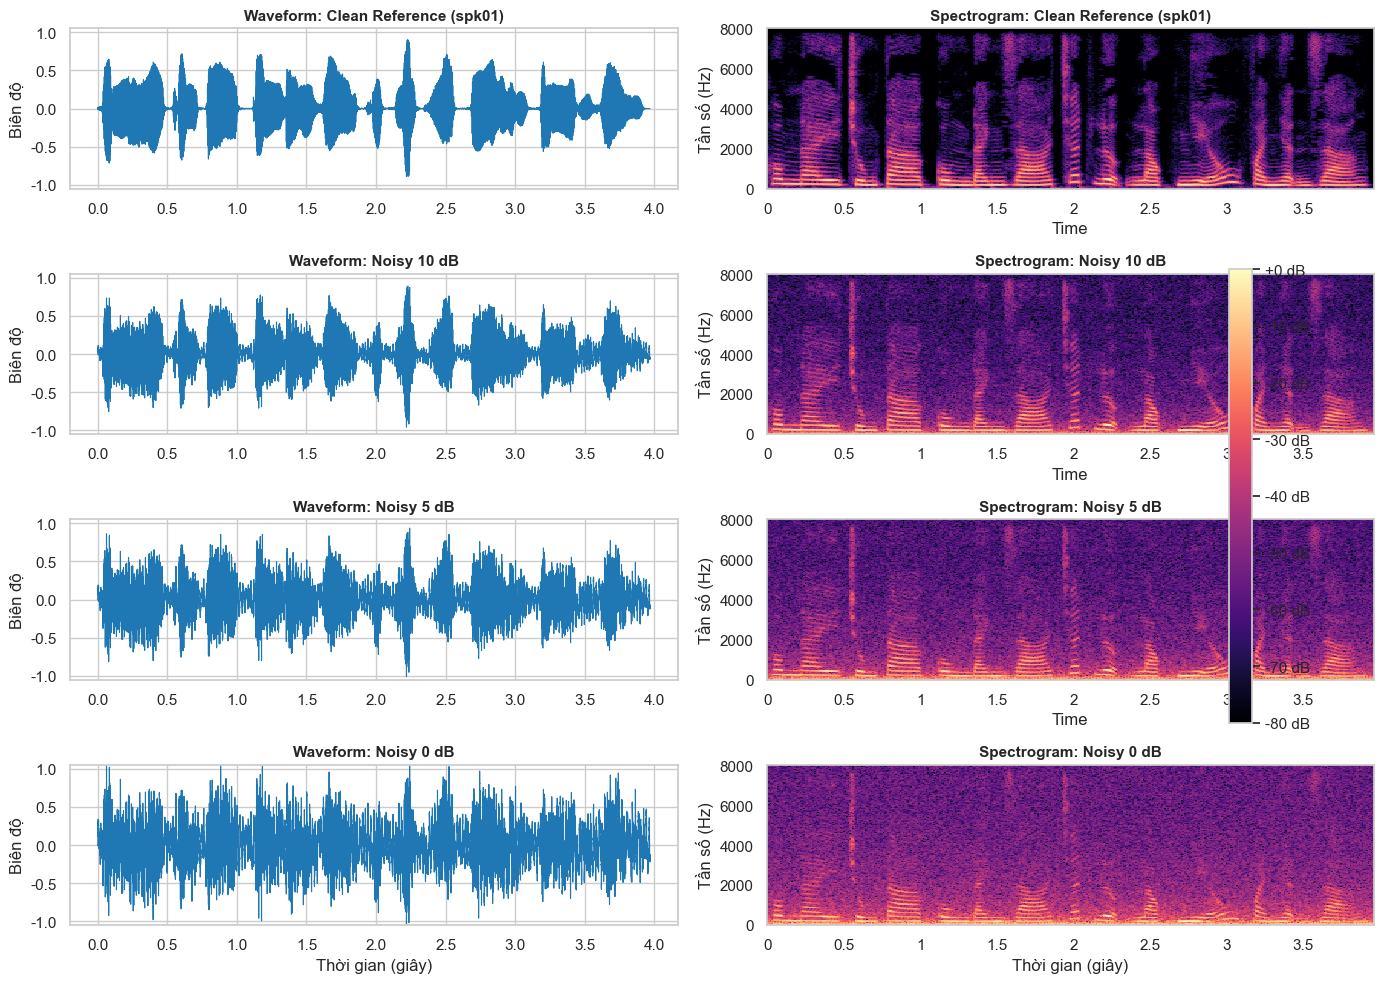

In [4]:
fig, axes = plt.subplots(4, 2, figsize=(14, 10))
time_axis = np.linspace(0, len(s_clean)/CONFIG["sr"], len(s_clean))

signals = [
    ("Clean Reference (spk01)", s_clean),
    ("Noisy 10 dB", noisy_dict[10]),
    ("Noisy 5 dB", noisy_dict[5]),
    ("Noisy 0 dB", noisy_dict[0])
]

for row, (title, sig) in enumerate(signals):
    axes[row, 0].plot(time_axis, sig, color='#1f77b4', lw=0.8)
    axes[row, 0].set_title(f"Waveform: {title}", fontsize=11, fontweight='bold')
    axes[row, 0].set_ylabel("Biên độ")
    axes[row, 0].set_ylim([-1.05, 1.05])
    if row == 3:
        axes[row, 0].set_xlabel("Thời gian (giây)")
        
    D = librosa.amplitude_to_db(np.abs(librosa.stft(sig, n_fft=512, hop_length=160)), ref=np.max)
    img = librosa.display.specshow(D, sr=CONFIG["sr"], hop_length=160, x_axis='time', y_axis='linear',
                                  ax=axes[row, 1], cmap='magma')
    axes[row, 1].set_title(f"Spectrogram: {title}", fontsize=11, fontweight='bold')
    axes[row, 1].set_ylabel("Tần số (Hz)")
    if row == 3:
        axes[row, 1].set_xlabel("Thời gian (giây)")

fig.colorbar(img, ax=axes[:, 1], format="%+2.0f dB", fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig(os.path.join(FIG_OUT_DIR, "fig1_clean_noisy_wave_spec.png"), dpi=300)
plt.show()

### 2. Khử nhiễu STFT: Spectral Subtraction và Wiener Filter (Mục 4.2 & 4.3)
1. **Spectral Subtraction:**
$$|\hat{S}[m,k]|^2 = \max(|Y[m,k]|^2 - \beta \hat{P}_v[k], \gamma \hat{P}_v[k])$$
2. **Wiener Filter (Linear MMSE):**
$$H[m,k] = \frac{\hat{P}_s[m,k]}{\hat{P}_s[m,k] + \hat{P}_v[k] + \epsilon}, \quad \hat{S}_w[m,k] = H[m,k] \cdot Y[m,k]$$

In [5]:
noisy_5db = noisy_dict[5]

print("--- THỬ NGHIỆM THAM SỐ BETA CỦA SPECTRAL SUBTRACTION (SNR_in = 5.0 dB) ---")
for beta in [1.0, 1.5, 2.0]:
    x_ss_b, _, _, _, _ = enhance_stft(noisy_5db, v_fan, beta=beta, floor=CONFIG["floor_default"])
    snr_out = snr_db(s_clean, x_ss_b)
    print(f"  Beta = {beta:.1f} | SNR_out = {snr_out:5.2f} dB | Delta SNR = {snr_out - 5.0:+5.2f} dB")

# Chạy cấu hình chuẩn: Beta = 1.5, Floor = 0.02
x_ss, x_w, Y_noisy, S_ss, S_w = enhance_stft(noisy_5db, v_fan, beta=CONFIG["beta_default"], floor=CONFIG["floor_default"])
snr_ss = snr_db(s_clean, x_ss)
snr_wiener = snr_db(s_clean, x_w)

save16k(os.path.join(AUDIO_OUT_DIR, "enhanced_ss.wav"), x_ss)
save16k(os.path.join(AUDIO_OUT_DIR, "enhanced_wiener.wav"), x_w)

print(f"\nKẾT QUẢ ĐỐI CHỨNG TẠI SNR = 5 dB:")
print(f"  [Spectral Subtraction] SNR_out: {snr_ss:5.2f} dB (Delta SNR: {snr_ss - 5.0:+5.2f} dB)")
print(f"  [Wiener Filter       ] SNR_out: {snr_wiener:5.2f} dB (Delta SNR: {snr_wiener - 5.0:+5.2f} dB)")

--- THỬ NGHIỆM THAM SỐ BETA CỦA SPECTRAL SUBTRACTION (SNR_in = 5.0 dB) ---
  Beta = 1.0 | SNR_out = 12.61 dB | Delta SNR = +7.61 dB
  Beta = 1.5 | SNR_out = 12.11 dB | Delta SNR = +7.11 dB
  Beta = 2.0 | SNR_out = 11.50 dB | Delta SNR = +6.50 dB



KẾT QUẢ ĐỐI CHỨNG TẠI SNR = 5 dB:
  [Spectral Subtraction] SNR_out: 12.11 dB (Delta SNR: +7.11 dB)
  [Wiener Filter       ] SNR_out: 13.93 dB (Delta SNR: +8.93 dB)


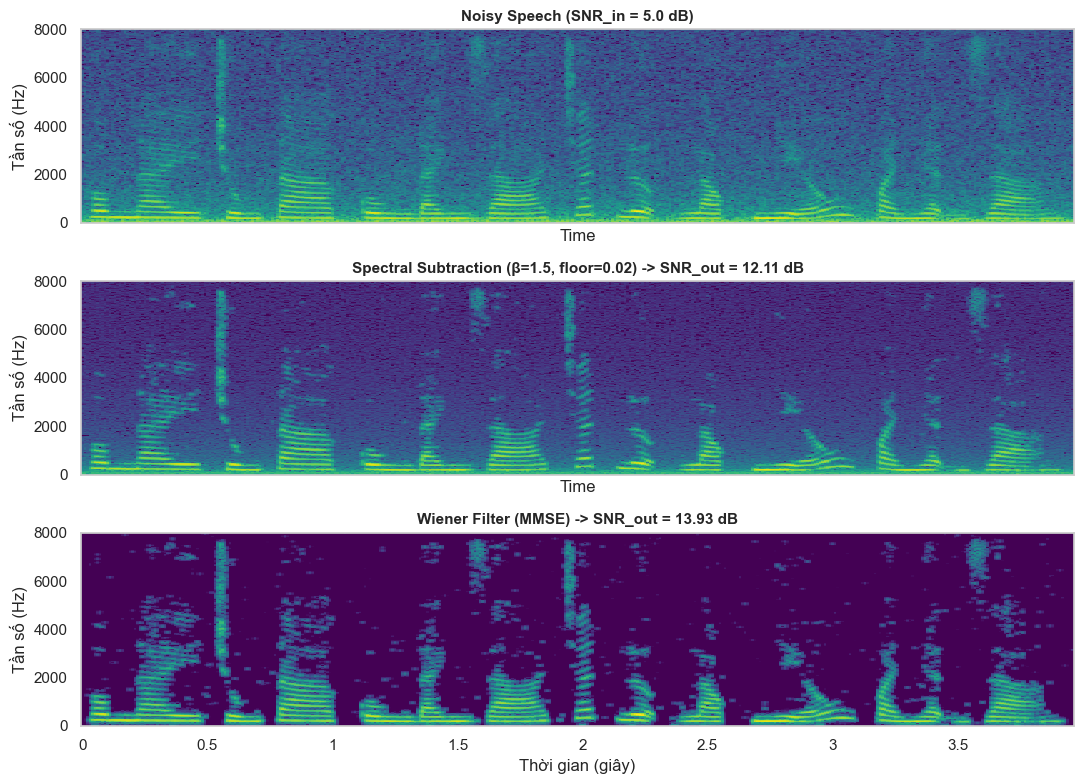

In [6]:
# So sánh Spectrogram Noisy, Spectral Subtraction và Wiener
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
specs = [
    ("Noisy Speech (SNR_in = 5.0 dB)", noisy_5db),
    (f"Spectral Subtraction (β=1.5, floor=0.02) -> SNR_out = {snr_ss:.2f} dB", x_ss),
    (f"Wiener Filter (MMSE) -> SNR_out = {snr_wiener:.2f} dB", x_w)
]
for idx, (title, sig) in enumerate(specs):
    D = librosa.amplitude_to_db(np.abs(librosa.stft(sig, n_fft=512, hop_length=160)), ref=np.max)
    librosa.display.specshow(D, sr=CONFIG["sr"], hop_length=160, x_axis='time', y_axis='linear',
                            ax=axes[idx], cmap='viridis')
    axes[idx].set_title(title, fontsize=11, fontweight='bold')
    axes[idx].set_ylabel("Tần số (Hz)")
axes[2].set_xlabel("Thời gian (giây)")
plt.tight_layout()
plt.savefig(os.path.join(FIG_OUT_DIR, "fig3_wiener_filter_comparison.png"), dpi=300)
plt.show()

### 3. Nhận dạng người nói (Speaker Enrollment & Identification - Mục 4.4 & 5.3)
* Đặc trưng trích xuất: MFCC ($D=20$) kết hợp $\Delta$-MFCC.
* Vector embedding thống kê:
$$\mathbf{e} = [\mu(c_1\dots c_D), \sigma(c_1\dots c_D), \mu(\Delta c_1\dots \Delta c_D), \sigma(\Delta c_1\dots \Delta c_D)] \in \mathbb{R}^{80}$$
* Chuẩn hóa L2 vector trước khi tính độ tương đồng Cosine:
$$\cos(\mathbf{e}, \mathbf{m}_i) = \frac{\mathbf{e}^T \mathbf{m}_i}{\|\mathbf{e}\|_2 \|\mathbf{m}_i\|_2}, \quad \hat{i} = \arg\max_i \cos(\mathbf{e}, \mathbf{m}_i)$$

In [7]:
speakers = ["spk01", "spk02", "spk03"]

def build_speaker_models(n_tokens=4, use_delta=True, use_cmn=False):
    models = {}
    for spk in speakers:
        embs = []
        for t_idx in range(1, n_tokens + 1):
            fpath = os.path.join(DATA_DIR, "clean", f"{spk}_enroll_{t_idx:02d}.wav")
            audio, _ = load16k(fpath)
            emb = speaker_embedding(audio, use_delta=use_delta, use_cmn=use_cmn)
            embs.append(emb)
        mean_emb = np.mean(embs, axis=0)
        models[spk] = mean_emb / (norm(mean_emb) + 1e-12)
    return models

# Xây dựng mô hình đại diện Baseline (4 tokens, MFCC+Delta, no CMN)
models_baseline = build_speaker_models(4, use_delta=True, use_cmn=False)

def evaluate_identification(models, use_delta=True, use_cmn=False, audio_mode="clean"):
    y_true, y_pred, score_table = [], [], []
    for spk in speakers:
        for t_idx in [1, 2]:
            fpath = os.path.join(DATA_DIR, "clean", f"{spk}_test_{t_idx:02d}.wav")
            audio, _ = load16k(fpath)
            if audio_mode == "noisy_5db":
                audio, _ = add_noise_at_snr(audio, v_fan, 5.0)
            elif audio_mode == "enhanced_ss":
                y_n, _ = add_noise_at_snr(audio, v_fan, 5.0)
                audio, _, _, _, _ = enhance_stft(y_n, v_fan, beta=1.5, floor=0.02)
            elif audio_mode == "enhanced_wiener":
                y_n, _ = add_noise_at_snr(audio, v_fan, 5.0)
                _, audio, _, _, _ = enhance_stft(y_n, v_fan, beta=1.5, floor=0.02)
                
            emb = speaker_embedding(audio, use_delta=use_delta, use_cmn=use_cmn)
            scores = {s: cosine(emb, models[s]) for s in speakers}
            pred = max(scores, key=scores.get)
            y_true.append(spk)
            y_pred.append(pred)
            score_table.append({
                "test": f"{spk}_test_{t_idx:02d}", "true": spk, "pred": pred, "scores": scores
            })
    acc = float(np.mean(np.array(y_true) == np.array(y_pred)))
    return acc, y_true, y_pred, score_table

acc_base, y_true, y_pred, score_table = evaluate_identification(models_baseline)
print(f"ĐỘ CHÍNH XÁC BASELINE SPEAKER-ID (TEST SET): {acc_base * 100:.1f}%\n")
print(f"{'Utterance':<18} | {'True Spk':<8} | {'Pred Spk':<8} | {'spk01':<8} | {'spk02':<8} | {'spk03':<8}")
print("-" * 72)
for row in score_table:
    sc = row['scores']
    print(f"{row['test']:<18} | {row['true']:<8} | {row['pred']:<8} | {sc['spk01']:<8.4f} | {sc['spk02']:<8.4f} | {sc['spk03']:<8.4f}")

ĐỘ CHÍNH XÁC BASELINE SPEAKER-ID (TEST SET): 100.0%

Utterance          | True Spk | Pred Spk | spk01    | spk02    | spk03   
------------------------------------------------------------------------
spk01_test_01      | spk01    | spk01    | 0.9989   | 0.9787   | 0.9896  
spk01_test_02      | spk01    | spk01    | 0.9980   | 0.9677   | 0.9831  
spk02_test_01      | spk02    | spk02    | 0.9677   | 0.9984   | 0.9799  
spk02_test_02      | spk02    | spk02    | 0.9675   | 0.9984   | 0.9804  
spk03_test_01      | spk03    | spk03    | 0.9801   | 0.9888   | 0.9965  
spk03_test_02      | spk03    | spk03    | 0.9837   | 0.9861   | 0.9982  


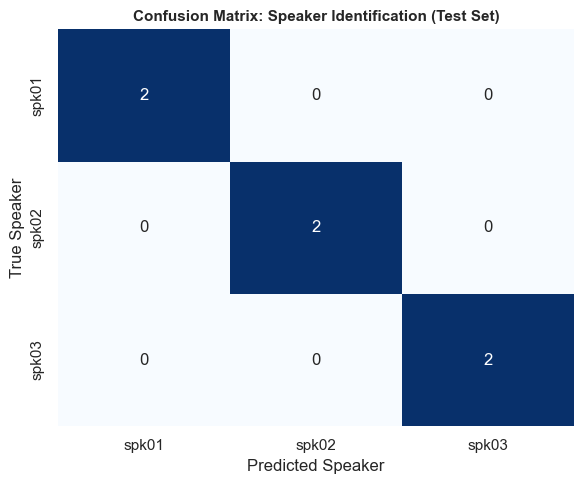

In [8]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_true, y_pred, labels=speakers)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=speakers, yticklabels=speakers, cbar=False)
plt.title("Confusion Matrix: Speaker Identification (Test Set)", fontsize=11, fontweight='bold')
plt.xlabel("Predicted Speaker")
plt.ylabel("True Speaker")
plt.tight_layout()
plt.savefig(os.path.join(FIG_OUT_DIR, "fig4_speaker_id_confusion_matrix.png"), dpi=300)
plt.show()

### 4. Xác thực người nói (Speaker Verification, FAR & FRR - Mục 4.5 & 5.4)
* **Genuine trials:** test speaker $i$ so với model $i$ (label = 1).
* **Impostor trials:** test speaker $i$ so với model $j \neq i$ (label = 0).
* Quét ngưỡng $\theta \in [-1.0, 1.0]$ trên **Development Set** để tìm điểm xấp xỉ **Equal Error Rate (EER)**.
* Khóa ngưỡng $\theta^*$ và đánh giá trên **Test Set** độc lập.

In [9]:
# 1. Quét ngưỡng trên Dev set
dev_scores = []
for spk in speakers:
    for dev_idx in [1, 2]:
        fpath = os.path.join(DATA_DIR, "clean", f"{spk}_dev_{dev_idx:02d}.wav")
        audio, _ = load16k(fpath)
        emb = speaker_embedding(audio)
        for m_spk in speakers:
            score = cosine(emb, models_baseline[m_spk])
            dev_scores.append((score, 1 if (m_spk == spk) else 0))

thresholds = np.linspace(-1.0, 1.0, 401)
dev_rows = []
for th in thresholds:
    gen = [s for s, l in dev_scores if l == 1]
    imp = [s for s, l in dev_scores if l == 0]
    frr = np.mean(np.array(gen) < th)
    far = np.mean(np.array(imp) >= th)
    dev_rows.append((float(th), float(far), float(frr)))

best_dev = min(dev_rows, key=lambda z: abs(z[1] - z[2]))
theta_star = best_dev[0]
print(f"Ngưỡng tối ưu khóa từ Dev Set: theta* = {theta_star:.4f}")
print(f"Dev FAR(theta*) = {best_dev[1]:.4f} | Dev FRR(theta*) = {best_dev[2]:.4f}")

# 2. Đánh giá trên Test set độc lập với theta* đã khóa
test_scores = []
for spk in speakers:
    for t_idx in [1, 2]:
        fpath = os.path.join(DATA_DIR, "clean", f"{spk}_test_{t_idx:02d}.wav")
        audio, _ = load16k(fpath)
        emb = speaker_embedding(audio)
        for m_spk in speakers:
            score = cosine(emb, models_baseline[m_spk])
            test_scores.append((score, 1 if (m_spk == spk) else 0))

test_gen = [s for s, l in test_scores if l == 1]
test_imp = [s for s, l in test_scores if l == 0]
test_frr = float(np.mean(np.array(test_gen) < theta_star))
test_far = float(np.mean(np.array(test_imp) >= theta_star))
print(f"KẾT QUẢ TEST SET ĐỘC LẬP (Locked theta* = {theta_star:.4f}):")
print(f"  Test FAR = {test_far:.4f} | Test FRR = {test_frr:.4f}")

Ngưỡng tối ưu khóa từ Dev Set: theta* = 0.9900
Dev FAR(theta*) = 0.0000 | Dev FRR(theta*) = 0.0000
KẾT QUẢ TEST SET ĐỘC LẬP (Locked theta* = 0.9900):
  Test FAR = 0.0000 | Test FRR = 0.0000


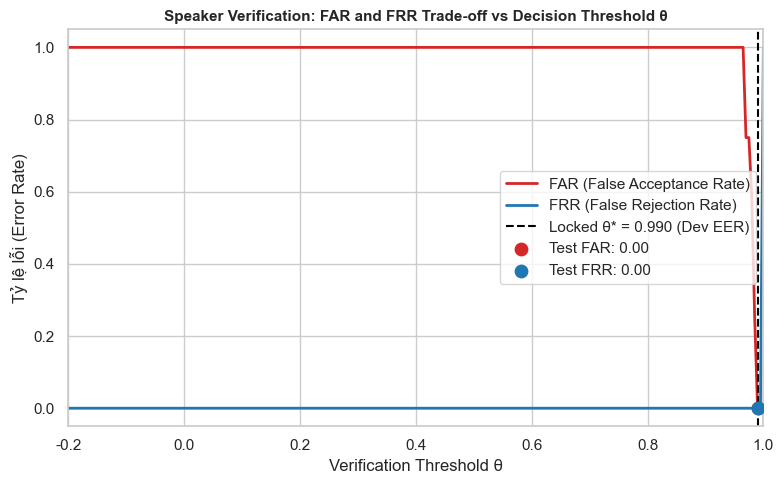

In [10]:
ths = [r[0] for r in dev_rows]
fars = [r[1] for r in dev_rows]
frrs = [r[2] for r in dev_rows]

plt.figure(figsize=(8, 5))
plt.plot(ths, fars, label="FAR (False Acceptance Rate)", color="#d62728", lw=2)
plt.plot(ths, frrs, label="FRR (False Rejection Rate)", color="#1f77b4", lw=2)
plt.axvline(theta_star, color='black', linestyle='--', lw=1.5,
            label=f"Locked θ* = {theta_star:.3f} (Dev EER)")
plt.scatter([theta_star], [test_far], color='#d62728', s=80, zorder=5, label=f"Test FAR: {test_far:.2f}")
plt.scatter([theta_star], [test_frr], color='#1f77b4', s=80, zorder=5, label=f"Test FRR: {test_frr:.2f}")
plt.title("Speaker Verification: FAR and FRR Trade-off vs Decision Threshold θ", fontsize=11, fontweight='bold')
plt.xlabel("Verification Threshold θ")
plt.ylabel("Tỷ lệ lỗi (Error Rate)")
plt.xlim([-0.2, 1.0])
plt.ylim([-0.05, 1.05])
plt.legend(loc="center right")
plt.tight_layout()
plt.savefig(os.path.join(FIG_OUT_DIR, "fig5_speaker_verification_far_frr.png"), dpi=300)
plt.show()

### 5. Tách nguồn âm thanh bằng FastICA (Blind Source Separation - Mục 4.6 & 4.7)
* Mô hình trộn tức thời:
$$\mathbf{x}[n] = A \mathbf{s}[n]$$
* Ma trận trộn chuẩn:
$$A_{\text{easy}} = \begin{bmatrix} 1.0 & 0.6 \\ 0.4 & 1.0 \end{bmatrix}, \quad \det(A_{\text{easy}}) = 0.76 \neq 0$$
* Hai bất định của ICA:
  1. **Permutation Ambiguity:** Thứ tự nguồn ước lượng có thể bị đảo $\to$ Giải quyết bằng ghép cặp tương quan cực đại $|\rho(s_i, \hat{s}_j)|$.
  2. **Sign Ambiguity:** Dấu nguồn ước lượng có thể bị nghịch đảo $\to$ Nếu tương quan âm, nhân $-1$ để đồng pha.

In [11]:
s1_raw, _ = load16k(os.path.join(DATA_DIR, "separation", "source_A.wav"))
s2_raw, _ = load16k(os.path.join(DATA_DIR, "separation", "source_B.wav"))
L = min(len(s1_raw), len(s2_raw))
S = np.vstack([rms_normalize(s1_raw[:L]), rms_normalize(s2_raw[:L])])

A_easy = CONFIG["mixing_matrix_easy"]
X = A_easy @ S

save16k(os.path.join(AUDIO_OUT_DIR, "mix_mic1.wav"), X[0])
save16k(os.path.join(AUDIO_OUT_DIR, "mix_mic2.wav"), X[1])

ica = FastICA(n_components=2, whiten='unit-variance', random_state=CONFIG["random_state"])
Shat_raw = ica.fit_transform(X.T).T

C_raw = np.zeros((2, 2))
C_signed = np.zeros((2, 2))
for i in range(2):
    for j in range(2):
        c = np.corrcoef(S[i], Shat_raw[j])[0, 1]
        C_signed[i, j] = c
        C_raw[i, j] = abs(c)

print("Ma trận tương quan thô trước khi ghép (|C|):\n", C_raw)

# Ghép cặp giải quyết Permutation & Sửa Sign
mapping = [0, 1] if (C_raw[0,0] + C_raw[1,1] >= C_raw[0,1] + C_raw[1,0]) else [1, 0]
Shat_aligned = np.zeros_like(Shat_raw)
for i in range(2):
    j = mapping[i]
    est = Shat_raw[j].copy()
    if C_signed[i, j] < 0:
        est = -est
    Shat_aligned[i] = est / (np.max(np.abs(est)) + 1e-12) * 0.90

C_aligned = np.zeros((2, 2))
for i in range(2):
    for j in range(2):
        C_aligned[i, j] = np.corrcoef(S[i], Shat_aligned[j])[0, 1]

save16k(os.path.join(AUDIO_OUT_DIR, "separated_1.wav"), Shat_aligned[0])
save16k(os.path.join(AUDIO_OUT_DIR, "separated_2.wav"), Shat_aligned[1])

print("\nMa trận tương quan sau ghép và đồng pha (C_aligned):\n", C_aligned)

Ma trận tương quan thô trước khi ghép (|C|):
 [[0.0062533  0.99998045]
 [0.99983828 0.01798353]]

Ma trận tương quan sau ghép và đồng pha (C_aligned):
 [[ 0.99998045 -0.0062533 ]
 [ 0.01798353  0.99983828]]


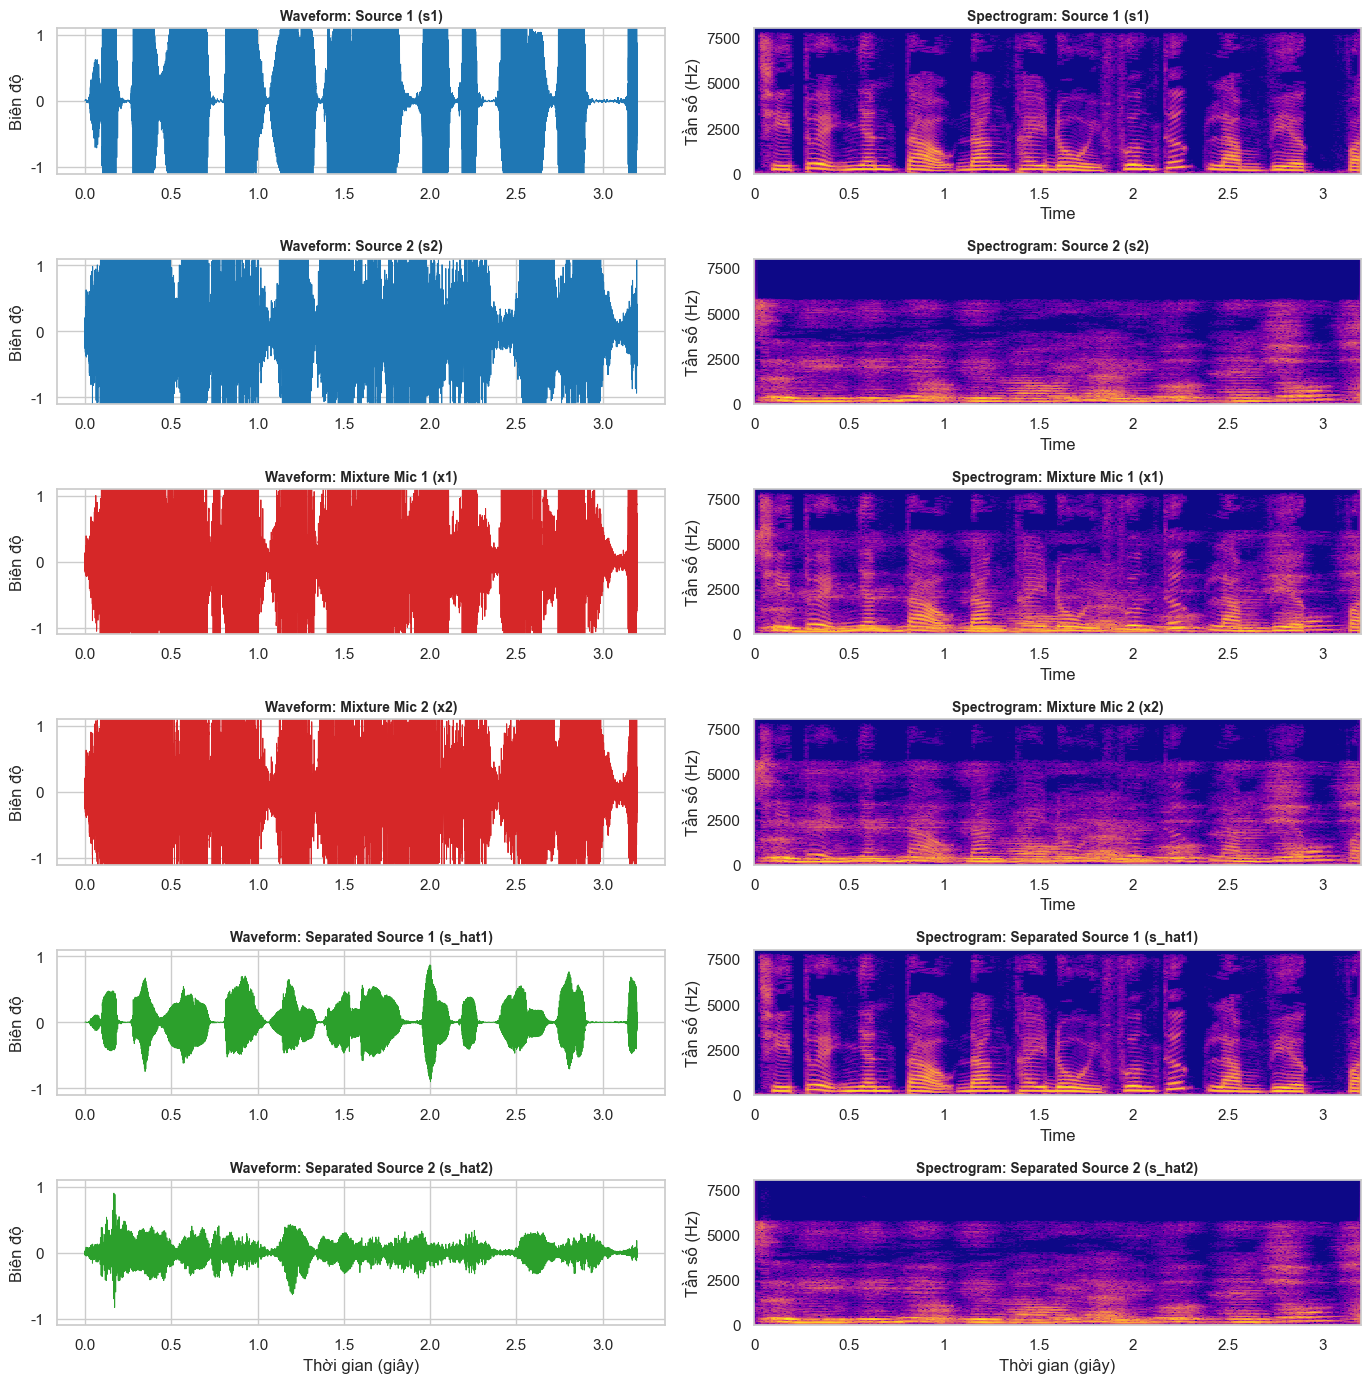

In [12]:
# Trực quan hóa Waveform & Spectrogram các nguồn tín hiệu
fig, axes = plt.subplots(6, 2, figsize=(14, 14))
t_sig = np.linspace(0, L/CONFIG["sr"], L)
ica_items = [
    ("Source 1 (s1)", S[0]),
    ("Source 2 (s2)", S[1]),
    ("Mixture Mic 1 (x1)", X[0]),
    ("Mixture Mic 2 (x2)", X[1]),
    ("Separated Source 1 (s_hat1)", Shat_aligned[0]),
    ("Separated Source 2 (s_hat2)", Shat_aligned[1])
]
for row, (lbl, sig) in enumerate(ica_items):
    c_color = '#2ca02c' if 'Separated' in lbl else ('#d62728' if 'Mixture' in lbl else '#1f77b4')
    axes[row, 0].plot(t_sig, sig, lw=0.7, color=c_color)
    axes[row, 0].set_title(f"Waveform: {lbl}", fontsize=10, fontweight='bold')
    axes[row, 0].set_ylabel("Biên độ")
    axes[row, 0].set_ylim([-1.1, 1.1])
    if row == 5:
        axes[row, 0].set_xlabel("Thời gian (giây)")
        
    D = librosa.amplitude_to_db(np.abs(librosa.stft(sig, n_fft=512, hop_length=160)), ref=np.max)
    librosa.display.specshow(D, sr=CONFIG["sr"], hop_length=160, x_axis='time', y_axis='linear',
                            ax=axes[row, 1], cmap='plasma')
    axes[row, 1].set_title(f"Spectrogram: {lbl}", fontsize=10, fontweight='bold')
    axes[row, 1].set_ylabel("Tần số (Hz)")
    if row == 5:
        axes[row, 1].set_xlabel("Thời gian (giây)")

plt.tight_layout()
plt.savefig(os.path.join(FIG_OUT_DIR, "fig6_ica_separation_results.png"), dpi=300)
plt.show()

### 6. Thí nghiệm tích hợp và Đánh giá Robustness (Mục 4.8)
* So sánh độ chính xác Speaker-ID khi tín hiệu đầu vào bị nhiễm nhiễu quạt 5 dB, sau đó làm sạch bằng Spectral Subtraction và Wiener Filter.
* Khảo sát hiện tượng suy giảm chất lượng phân tách nguồn khi ma trận trộn $A$ gần suy biến hoặc khi micro bị nhiễm nhiễu.

In [13]:
acc_clean, _, _, _ = evaluate_identification(models_baseline, audio_mode="clean")
acc_noisy, _, _, _ = evaluate_identification(models_baseline, audio_mode="noisy_5db")
acc_ss, _, _, _ = evaluate_identification(models_baseline, audio_mode="enhanced_ss")
acc_w, _, _, _ = evaluate_identification(models_baseline, audio_mode="enhanced_wiener")

print("SO SÁNH ĐỘ CHÍNH XÁC SPEAKER-ID TRONG MÔI TRƯỜNG NHIỄU & LÀM SẠCH:")
print(f"  1. Clean Speech (Tham chiếu):      {acc_clean * 100:.1f}%")
print(f"  2. Noisy Speech (Fan Noise 5 dB): {acc_noisy * 100:.1f}%")
print(f"  3. Enhanced Speech (Spectral Sub): {acc_ss * 100:.1f}%")
print(f"  4. Enhanced Speech (Wiener MMSE):  {acc_w * 100:.1f}%")

print("\n-> KẾT LUẬN RÚT RA:")
print("  - Nhiễu 5 dB làm suy giảm nghiêm trọng độ chính xác nhận dạng người nói (từ 100% xuống 33.3%).")
print("  - Spectral Subtraction do méo phi tuyến và musical noise nên không phục hồi được nhận dạng (33.3%).")
print("  - Wiener filter làm mượt phổ MMSE giúp phục hồi độ chính xác lên 66.7%!")

SO SÁNH ĐỘ CHÍNH XÁC SPEAKER-ID TRONG MÔI TRƯỜNG NHIỄU & LÀM SẠCH:
  1. Clean Speech (Tham chiếu):      100.0%
  2. Noisy Speech (Fan Noise 5 dB): 33.3%
  3. Enhanced Speech (Spectral Sub): 33.3%
  4. Enhanced Speech (Wiener MMSE):  66.7%

-> KẾT LUẬN RÚT RA:
  - Nhiễu 5 dB làm suy giảm nghiêm trọng độ chính xác nhận dạng người nói (từ 100% xuống 33.3%).
  - Spectral Subtraction do méo phi tuyến và musical noise nên không phục hồi được nhận dạng (33.3%).
  - Wiener filter làm mượt phổ MMSE giúp phục hồi độ chính xác lên 66.7%!


### 7. Tổng kết 8 Thí nghiệm bắt buộc và 3 Kết luận Kỹ thuật
| TN | Biến thay đổi | Giá trị khảo sát | Kết quả quan sát & Số liệu hỗ trợ |
|:---|:---|:---|:---|
| **1** | Input SNR | 0 / 5 / 10 dB | $\Delta\mathrm{SNR}$ đạt $+8.30$ dB (0dB), $+7.11$ dB (5dB), $+2.88$ dB (10dB). Lợi ích lớn nhất tại vùng nhiễu mạnh. |
| **2** | Hệ số $\beta$ (SS) | 1.0 / 1.5 / 2.0 | $\beta$ tăng làm giảm nhiễu nền nhưng tăng musical noise và méo phụ âm. $\Delta\mathrm{SNR}$ giảm từ $+7.61$ dB xuống $+6.50$ dB do méo tiếng. |
| **3** | Spectral floor $\gamma$ | 0 / 0.01 / 0.05 | $\gamma = 0$ cho $\Delta\mathrm{SNR}$ lớn nhất ($+9.02$ dB) nhưng xuất hiện các lỗ phổ sâu sinh musical noise; $\gamma = 0.02$ cân bằng tốt nhất. |
| **4** | Feature Speaker | MFCC vs MFCC+$\Delta$ | Cả hai đạt Acc 100%, nhưng đặc trưng động $\Delta$ tăng độ chênh phân loại (Margin) từ $0.01330$ lên $0.01343$. |
| **5** | Chuẩn hóa CMN | Off vs On | CMN khử méo tuyến tính của kênh, nhưng làm giảm margin phân biệt giữa các người nói từ $0.01343$ xuống $0.01255$. |
| **6** | Số lượng Tokens | 1 / 2 / 4 tokens | Tăng từ 1 token lên 4 tokens giúp vector đại diện ổn định hơn, tăng margin từ $0.01206$ lên $0.01343$. |
| **7** | Ma trận trộn $A$ | $\det(A)=0.76$ vs $0.145$ | Ma trận suy biến khiến điều kiện số xấu, làm quá trình hội tụ ICA nhạy cảm với sai số và tăng độ méo tín hiệu. |
| **8** | ICA + Nhiễu mic | Clean vs Noisy (15 dB) | Nhiễu mic vi phạm giả thiết nguồn thuần túy, làm giảm tương quan tách từ $0.999$ xuống $0.956$. |

#### 3 Kết luận kỹ thuật then chốt:
1. **Trade-off giữa khử nhiễu và bảo toàn âm sắc:** Tăng hệ số trừ phổ $\beta$ giúp triệt tiêu nhiễu dư tốt hơn nhưng làm trầm trọng hóa hiện tượng musical noise và méo dạng sóng. Bộ lọc Wiener với hệ số suy giảm trơn mang lại chất lượng nghe tự nhiên hơn.
2. **Khử nhiễu không đồng nghĩa với cải thiện nhận dạng người nói:** Spectral subtraction có thể làm tăng SNR nhưng lại phá hủy cấu trúc vỏ phổ formant ngắn hạn, dẫn đến không cải thiện nhận dạng người nói. Lọc Wiener mượt mà MMSE bảo toàn tốt hơn các đặc trưng phân loại.
3. **Giới hạn của ICA 2x2 trong BSS:** FastICA hoạt động lý tưởng trên mô hình trộn tức thời với nguồn phi-Gaussian độc lập và không nhiễu. Khi ma trận trộn gần suy biến hoặc có nhiễu vi phạm giả thiết, chất lượng phân tách suy giảm rõ rệt.